# ASTRID2 (0.58 GeV) を notebook で

ASTRID2 のラティス (`example/astrid/lattice/ASTRID2_v01_01.sad`。0.58 GeV。30° の複合機能偏向磁石 (K1≠0) を持つ) を読み込み、example/astrid の例のコマンドを順に流します。最後に、pysad 独自の解析式 (`AmplitudeTuneShift[]`・`ResonanceDrivingTerms[]`。gs には無い) も流します (解析の検証は docs/25 §11)。**最初にラティスを貼り、`%%sad` で最初の計算をして、`%%sad --continue` で続きを流します**。

出力は pysad (既定の `v2`) の実行結果です。K64 (gs) と同じ動作にするときは、最初に `PYSAD_COMPAT=k64` を環境変数に置きます。各例の md には、gs と pysad の出力の比較があります。このファイルは `example/tools/make_ring_notebooks.py` で作りました (元の .sad から機械的に取り出しています)。

In [1]:
%load_ext pysad.notebook

## 0. ラティスを読み込む: ASTRID2 v01_01 (0.58 GeV)

`%%sad lattice` は、ラティスを保存します (まだ実行しません)。

In [2]:
%%sad lattice
!********************************************************************
!*
!*   ASTRID2 - THE ULTIMATE SYNCHROTRON RADIATION SOURCE
!*   http://www.isa.au.dk/facilities/astrid2/astrid2.asp
!*
!********************************************************************

MOMENTUM= 0.58 GEV;

MARK
	MKS   =()
	MKE   =()
;

MONI
	PM     =()
;

CAVI
	CAVI=(VOLT= 50000 FREQ = 104950000)
;

BEND
	PV = ( L = 0    K0 = 0     ROTATE =-90 DEG ) 
	PH = ( L = 0    K0 = 0  )
;

QUAD
	QF3 = ( L =0.1800 K1 =5.939500*0.1800 )
	QF2 = ( L =0.1800 K1 =6.070000*0.1800 )
;

SEXT
	SF = ( L =0.0750   K2 =   125.62*0.0750 )
	SD = ( L =0.1500   K2 =   -81.93*0.15 )
;

BEND
	BH = (L = 0.8500 ANGLE = 0.523599 K1 = -1.678200*0.8500  E1=0 E2=0)
;

DRIFT
	D14837    = (L = 1.4837 )
	D0100     = (L = 0.1000 )
	D0180     = (L = 0.1800 )
	D0190     = (L = 0.1900 )
	D0120     = (L = 0.1200 )
;

LINE
	HV    = (PH PV)
	NCELL
	=(MKS
	  D14837 PM D0100 QF3  D0180 HV D0180 
          BH 
          D0190 SD D0120 QF2 D0120 SF
          PM
	  SF D0120 QF2 D0120 SD D0190 
          BH D0180 HV D0180 QF3 D0100 PM D14837
          MKE) 

	RING = (3*NCELL CAVI 3*NCELL)
        RINGMPW = (3*NCELL CAVI 3*NCELL)
!	RING = (6*CELL)
;
 SEXT   SD      =(L =.15  K2 =-11.729486011842393 )
        SF      =(L =.075 K2 =8.681418961367605 )
 ;


(pysad) ラティス 'main' を保存しました (69 行。保存中: main)。コマンドは `%%sad` のセルに書きます


## 1. セルの計算とエミッタンス

`USE RING; cell calc emit;` と主なパラメータの印字です (`tune_radiation/calc_RadInt_ASTRID2.sad` の冒頭と同じ計算)。

In [3]:
%%sad
! 元の例のスクリプトと同じフラグ (FFS の前に置く)
ON RAD COD RFSW RADCOD;
OFF FLUC;
FFS;
USE RING;
cell calc emit;
Print["circumference [m] = ", LINE["S","$$$"]];
Print["tune nx ny = ", Twiss["NX","$$$"]/2/Pi, " ", Twiss["NY","$$$"]/2/Pi];
Print["EMITX [m rad] = ", EMITX, "  SIGE = ", SIGE];
Print["MOMENTUM [eV] = ", MOMENTUM];


 Matched. (  0.000    ) DP = 0.01000  DP0 = 0.00000  ExponentOfResidual = 2.0  OffMomentumWeight =   1.000  CALEXP  


$$$       f AX    #######  #  2.889E-15 $$$       f BX    #######  #   3.891569 $$$       f NX    #######  #   5.179990


$$$       f AY    #######  #  -1.27E-15 $$$       f BY    #######  #   1.622525 $$$       f NY    #######  #   2.140178


$$$       f LENG  #######  #  45.704400



    Closed orbit:


                  x     px/p0         y     py/p0         z     dp/p0 


... (30 outputs left out)

circumference [m] = 45.70439999999998


tune nx ny = 5.179989880729472 2.140177571949129


EMITX [m rad] = 1.2680433830758065e-8  SIGE = .0004326088253684417


MOMENTUM [eV] = 5.8e8


## 2. β 関数と分散関数を描く

`sad.value()` で全要素の値を取り出して、Python で描きます。

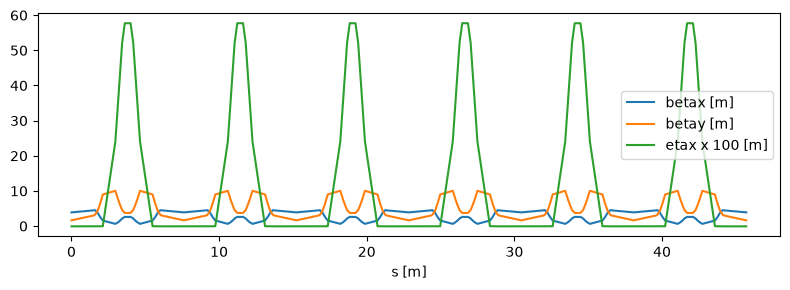

要素の数 200  周長 [m] 45.70439999999998


In [4]:
import matplotlib.pyplot as plt
s  = sad.value('Twiss["S","*"]')
bx = sad.value('Twiss["BX","*"]'); by = sad.value('Twiss["BY","*"]'); ex = sad.value('Twiss["EX","*"]')
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(s, bx, label='betax [m]'); ax.plot(s, by, label='betay [m]'); ax.plot(s, [100 * e for e in ex], label='etax x 100 [m]')
ax.set_xlabel('s [m]'); ax.legend(); fig.tight_layout(); plt.show()
print('要素の数', len(s), ' 周長 [m]', s[-1])

## 3. 放射積分 (`tune_radiation/calc_RadInt_ASTRID2.sad`)

複合機能偏向磁石 (K1≠0) の中の積分 (I4 の勾配の項、H の積分) を、解析式で求めて `cell calc emit` と比べます。

In [5]:
%%sad --continue
bposi = LINE["POSITION","B*"];

GetIntegralCH[num_]:=(
    IH = 0;
   bex = Twiss["BX",num+0.5];
   alx = Twiss["AX",num+0.5];
   gax = (1+alx*alx)/bex;
   etx = Twiss["EX",num+0.5];
   epx = Twiss["EPX",num+0.5];
   L   = LINE["L",num]/2;
   tha = LINE["ANGLE",num]/2;
   rho = L/tha;
   k1  = -1*LINE["K1",num];
   k   = k1/L/2;
   kef2= k - 1/rho/rho;
   If[kef2>0,
   kef = Sqrt[kef2];
   aaa = 2*(-8*kef^2*rho*epx*Sinh[kef*L]+8*kef^3*(kef^2*etx*rho+1)*rho*epx*L)/4/kef^5/rho^2;
   bbb = 2*(kef^2*Sinh[2*kef*L]+4*kef^5*rho^2*epx^2*L-2*kef^3*L)/4/kef^5/rho^2;
   ccc = 2*(-8*(1+kef^2*rho*etx)*Sinh[kef*L]+6*kef*L+4*kef^5*rho^2*etx^2*L+Sinh[2*kef*L]+8*kef^3*rho*etx*L)/4/kef^5/rho^2;
   IH = IH + aaa * alx + bbb * bex + ccc * gax;
    ,
   kef = Sqrt[-kef2];
   aaa = 2*(8*kef^2*rho*epx*Sin[kef*L]+8*kef^3*(kef^2*etx*rho-1)*rho*epx*L)/4/kef^5/rho^2;
   bbb = 2*(-kef^2*Sin[2*kef*L]+4*kef^5*rho^2*epx^2*L+2*kef^3*L)/4/kef^5/rho^2;
   ccc = 2*(-8*(1-kef^2*rho*etx)*Sin[kef*L]+6*kef*L+4*kef^5*rho^2*etx^2*L+Sin[2*kef*L]-8*kef^3*rho*etx*L)/4/kef^5/rho^2;
   IH = IH + aaa * alx + bbb * bex + ccc * gax;
   ];
   IH = IH /rho/rho/Abs[rho];
   IH
);

GetIntegralEX[num_]:=(
   IE = 0;
   etx = Twiss["EX",num+0.5];
   epx = Twiss["EPX",num+0.5];
   L   = LINE["L",num]/2;
   tha = LINE["ANGLE",num]/2;
   rho = L/tha;
   k1  = -1*LINE["K1",num];
   k   = k1/L/2;
   kef2= k - 1/rho/rho;
   If[kef2>0,
   kef = Sqrt[kef2];
   IE = ((etx*kef^2*rho+1)*Sinh[kef*L]+epx*kef*rho*Cosh[kef*L]-kef*L-kef*rho*epx)/kef^3/rho;
   etx = Twiss["EX",num+0.5];
   epx = -1*Twiss["EPX",num+0.5];
   IE = IE + ((etx*kef^2*rho+1)*Sinh[kef*L]+epx*kef*rho*Cosh[kef*L]-kef*L-kef*rho*epx)/kef^3/rho;
   ,
   kef = Sqrt[-kef2];
   IE = ((etx*kef^2*rho-1)*Sin[kef*L]-epx*kef*rho*Cos[kef*L]+kef*L+kef*rho*epx)/kef^3/rho;
   etx = Twiss["EX",num+0.5];
   epx = -1*Twiss["EPX",num+0.5];
   IE = IE + ((etx*kef^2*rho-1)*Sin[kef*L]-epx*kef*rho*Cos[kef*L]+kef*L+kef*rho*epx)/kef^3/rho;
   ];
   IE
);
Jx = 0;
Jy = 0;
Jz = 0;
DFac   = 0;
RadIntI1 = 0;
RadIntI2 = 0;
RadIntI3 = 0;
RadIntI4 = 0;
RadIntI5 = 0;

   Do[
      IH = GetIntegralCH[bposi[i]];
      RadIntI5 = RadIntI5 + IH;
   ,{i,Length[bposi]}];


   Do[
      IE = GetIntegralEX[bposi[i]];
      L   = LINE["L",bposi[i]];
      tha = LINE["ANGLE",bposi[i]];
      rho = L/tha;
      k1  = -LINE["K1",bposi[i]]/L;
      RadIntI1  = RadIntI1 + IE / rho;
      RadIntI2  = RadIntI2 + tha*tha/L;
      RadIntI3  = RadIntI3 + L / rho / rho / Abs[rho];
      RadIntI4  = RadIntI4 + IE*(1/rho^3-2*k1/rho);
   ,{i,Length[bposi]}];

   Print["I1 I2 I3 I4 I5 = ",RadIntI1," ",RadIntI2," ",RadIntI3," ",RadIntI4," ",RadIntI5];
   DFac = RadIntI4 / RadIntI2;

   sademit = Emittance[];

   Jx = 1 - DFac;
   Jy = 1;            !!!!!!!  only varid for the case without vertical bendings.
   Jz = 2 + DFac;
   Print["Jx Jy Jz = ",Jx," ",Jy," ",Jz];

   cq = 3.832e-13;
   Cq2 = cq;
   gamma = MOMENTUM / 1000000/0.51099906;
   resemit = cq * gamma * gamma * RadIntI5 / RadIntI2 /  Jx;
   Print["emitx from integrals = ",resemit];
   Print["emitx from Emittance[] = ",(Emittances/.sademit)[1]];
   Print["U0 [eV] Emittance[] = ",EnergyLossU0/.sademit];
   Print["U0 [eV] from I2 = ",8.846e-5*(MOMENTUM/1e9)^4*RadIntI2/2/Pi*1e9];
   Print["alpha_c = ",MomentumCompaction/.sademit,"   alpha_c from I1/C = ",RadIntI1/Twiss["S","$$$"]];
   Print["Edamp: Jz=",Jz,"  sigE = ",Sqrt[Cq2*gamma^2*RadIntI3/(Jz*RadIntI2)], "   Emittance[] sigE = ", MomentumSpread/.sademit];


I1 I2 I3 I4 I5 = .4876738554155279 3.8704364160141185 2.38418427881009 -1.4517784646756722 .13670707236100957


Jx Jy Jz = 1.3750942551772374 1 1.6249057448227626


emitx from integrals = 1.2680601742795952e-8


emitx from Emittance[] = 1.2680433830758413e-8


U0 [eV] Emittance[] = 6166.703905026149


U0 [eV] from I2 = 6166.503440413915


alpha_c = .010669400952052965   alpha_c from I1/C = .01067017301212855


Edamp: Jz=1.6249057448227626  sigE = .0004326099428974352   Emittance[] sigE = .00043260882502963377


## 4. 振幅依存チューンシフト (`tune_radiation/amp_dep_ts_ASTRID2.sad`)

`ins calc` で 1 周のチューンを求めて、楕円上で平均します。

In [6]:
%%sad --continue
AmplitudeDependentTuneShift[nx_, ny_, thetadiv_] := (
   FFS["cell calc emit"];
   dth = 2 * Pi / thetadiv;
   deptunetemp = Table[{1,2},{thetadiv}];
   ith = 0;
   Do[
      ith = ith + 1;
      inidx  = nx * Sqrt[w] * Sqrt[betax]*Cos[theta];
      inidpx = nx * Sqrt[w] * 1/Sqrt[betax]*(Sin[theta]-alphax*Cos[theta]);
      inidy  = ny * Sqrt[w] * Sqrt[betay]*Cos[theta];
      inidpy = ny * Sqrt[w] * 1/Sqrt[betay]*(Sin[theta]-alphay*Cos[theta]);
      deptunetemp[ith] = CalcAmpDepTS[inidx,inidpx,inidy,inidpy];
   ,{theta, 0, 2 * Pi - dth/2, dth}];
   deptune = {0,0};
   Do[ deptune = deptune + deptunetemp[ith]; ,{ith,thetadiv}];
   deptune = deptune / thetadiv;
   deptune
);

CalcAmpDepTS[inidx_,inidpx_,inidy_,inidpy_] := (
   ininame = LINE["NAME",1];
   LINE["DX" ,ininame] = inidx;
   LINE["DPX",ininame] = inidpx;
   LINE["DY" ,ininame] = inidy;
   LINE["DPY",ininame] = inidpy;
   FFS["ins calc"];
   nux = Twiss["NX","$$$"]/2/Pi;
   nuy = Twiss["NY","$$$"]/2/Pi;
   {nux,nuy}
);

SetInitialParameters[] := (
   FFS["cell calc emit fix"];
   alphax = Twiss["AX",1];  betax  = Twiss["BX",1];
   alphay = Twiss["AY",1];  betay  = Twiss["BY",1];
   w  = EMITX;
);

USE RING;
cell calc emit;
DP = 0;
SetInitialParameters[];
Print["EMITX = ", EMITX, "  betax betay at MKS = ", betax, " ", betay];
nu0 = AmplitudeDependentTuneShift[0, 0, 1];
Print["ADTS amplitude 0: ", nu0];

amps = {10,20,30,40,60,80};
Do[
   SetInitialParameters[];
   res = AmplitudeDependentTuneShift[amps[k],1,8];
   Print["ADTS-X  ", amps[k], " sigma  ", res[1], " ", res[2]];
,{k,1,6}];

DX 0;  DY 0;  DPX 0;  DPY 0;
cell calc emit;

Do[
   SetInitialParameters[];
   res = AmplitudeDependentTuneShift[1, amps[k], 8];
   Print["ADTS-Y  ", amps[k], " sigma  ", res[1], " ", res[2]];
,{k,1,6}];


 Matched. (  0.000    ) DP = 0.01000  DP0 = 0.00000  ExponentOfResidual = 2.0  OffMomentumWeight =   1.000  CALEXP  


$$$       f AX    #######  #  2.889E-15 $$$       f BX    #######  #   3.891569 $$$       f NX    #######  #   5.179990


$$$       f AY    #######  #  -1.27E-15 $$$       f BY    #######  #   1.622525 $$$       f NY    #######  #   2.140178


$$$       f LENG  #######  #  45.704400



    Closed orbit:


                  x     px/p0         y     py/p0         z     dp/p0 


... (77 outputs left out)

ADTS-Y  30 sigma  5.188638005157462 2.1574333312642144


ADTS-Y  40 sigma  5.19589321172333 2.1711458929086898


ADTS-Y  60 sigma  5.219460692665371 2.2114381521923057


ADTS-Y  80 sigma  5.259014385590945 2.268465499493415


## 5. pysad 独自の解析式: ADTS と共鳴駆動項 (gs には無い)

`AmplitudeTuneShift[]` (解析) と `ResonanceDrivingTerms[]` を、ラティスの光学から求めます。偏向磁石の 3 次の項 (複合機能の本体・端) は、追跡の写像から取り出して入れてあります (docs/25 §8)。

In [7]:
%%sad --continue
USE RING; cell calc emit; DP0 = 0; DP = 0;
Print["ADTS analytic ", AmplitudeTuneShift[]];
Print["RDT ", ResonanceDrivingTerms[Terms->{"h21000","h30000","h10110","h10020","h10200"}]];


 Matched. (  0.000    ) DP = 0.01000  DP0 = 0.00000  ExponentOfResidual = 2.0  OffMomentumWeight =   1.000  CALEXP  


$$$       f AX    #######  #  7.3888E-9 $$$       f BX    #######  #   3.891569 $$$       f NX    #######  #   5.179990


$$$       f AY    #######  #  -5.740E-9 $$$       f BY    #######  #   1.622525 $$$       f NY    #######  #   2.140178


$$$       f LENG  #######  #  45.704400



    Closed orbit:


                  x     px/p0         y     py/p0         z     dp/p0 


... (28 outputs left out)

Beam size xi           =  .22214166 mm  Beam size eta          =  .00000000 mm


Nominal spin tune      =  1.3162425     Polarization time      =   .0000000 min



ADTS analytic {DNuxDJx->440.3049995060362,DNuxDJy->1294.5656213923878,DNuyDJy->1127.5467910297527,Sextupole->{440.3049995060362,
 1294.5656213923878,1127.5467910297527},Octupole->{0,0,0},Kinematic->{14.800720715811996,12.745233469424958,29.366573050950603},
 QuadFringe->{67.3726754084311,197.00669991809093,231.72838445351186},BendFourth->{0,0,0},BendCubic->{-.11713202926526761,
 24.59045408815311,-25.085469010859367},SextBendCross->{-52.53633770240722,-225.16877983982928,119.42368610171242},Rotate->{0,0,0},
 Total->{469.8249258986069,1303.7392290282276,1482.9799656250682}}


RDT {H21000->{2.3531724378346386,1.4932606281668939},H30000->{-.13842175150225455,1.096560211039158},H10110->{9.066582803154331,
 5.753416371500098},H10020->{-2.7680066144339253,.9028879141544266},H10200->{-.40529555388165717,-3.236460064702581}}


## 6. 運動量依存チューンシフト (`tune_radiation/mom_dep_ts_ASTRID2.sad`)

δ を −2〜+4% で振って、6 極あり・なし (`S* 0`) のチューンを求め、多項式でフィットします。**6 極を切るので、最後に流します**。

In [8]:
%%sad --continue
  DP = 0;
  tx = {}; ty = {};
  dlist = Range[-0.02, 0.04, 0.005];
  Do[
      DP0 = dlist[i];
      FFS["cell calc"];
      nx = Twiss["NX","$$$"]/2/Pi; ny = Twiss["NY","$$$"]/2/Pi;
      tx = Append[tx, {dlist[i], nx}];
      ty = Append[ty, {dlist[i], ny}];
      Print["SEXT-ON  ", dlist[i], " ", nx, " ", ny];
  ,{i,1,Length[dlist]}];
  cx = PolynomialFit[tx,3]; cy = PolynomialFit[ty,3];
  Print["SEXT-ON fit x: ", cx];
  Print["SEXT-ON fit y: ", cy];

  DP0 = 0;
  FFS["cell calc"];
  ! 6 極の寄与を式 (1/4pi) sum(+-) K2 EX B で数える (薄肉、要素の中点の値) 
  sp = LINE["POSITION","S*"];
  xsx = 0; xsy = 0;
  Do[
      k2 = LINE["K2", sp[i]];
      ex = Twiss["EX", sp[i]+0.5];
      xsx = xsx + k2*ex*Twiss["BX", sp[i]+0.5];
      xsy = xsy - k2*ex*Twiss["BY", sp[i]+0.5];
  ,{i,1,Length[sp]}];
  Print["sextupole xi_x, xi_y from formula = ", xsx/4/Pi, " ", xsy/4/Pi, "   (#sext = ", Length[sp], ")"];
  S* 0;
  tx = {}; ty = {};
  Do[
      DP0 = dlist[i];
      FFS["cell calc"];
      nx = Twiss["NX","$$$"]/2/Pi; ny = Twiss["NY","$$$"]/2/Pi;
      tx = Append[tx, {dlist[i], nx}];
      ty = Append[ty, {dlist[i], ny}];
      Print["SEXT-OFF ", dlist[i], " ", nx, " ", ny];
  ,{i,1,Length[dlist]}];
  cx = PolynomialFit[tx,3]; cy = PolynomialFit[ty,3];
  Print["SEXT-OFF fit x: ", cx];
  Print["SEXT-OFF fit y: ", cy];


SEXT-ON  -.02 5.193861344166958 2.156636088369486


SEXT-ON  -.015 5.187820834046984 2.1493734773756157


SEXT-ON  -.01 5.183450877785037 2.1441848373123147


SEXT-ON  -.005000000000000001 5.180813263761388 2.141103238914949


SEXT-ON  0 5.179989896765285 2.140177602841538


SEXT-ON  .005000000000000001 5.181087102866808 2.1414756279444966


... (21 outputs left out)

SEXT-OFF .035 4.986715237035296 1.774485447487556


SEXT-OFF .039999999999999994 4.962181049430639 1.7272314409326408


SEXT-OFF fit x: {{5.179892414868791,-6.253771616333017,27.884516294131434,-194.0745299470934},{Residual->.00021754153038181087}}


SEXT-OFF fit y: {{2.1397747822685362,-11.94047903464323,66.21726678522626,-653.0515220044832},{Residual->.000840652679930372}}
